In [4]:
# Import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [7]:
# Load Titanic dataset
df = pd.read_csv('titanic.csv')

# Select features and target
X = df[['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare']]
y = df['survived']

# Convert categorical data into numerical data
X = pd.get_dummies(X, columns=['sex'], drop_first=True)

# Handle missing values
imputer = SimpleImputer(strategy='median')
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [8]:
# Bagging classifier
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50,
    random_state=42
)

bagging.fit(X_train, y_train)
y_pred_bag = bagging.predict(X_test)


In [9]:

# Boosting classifier (AdaBoost)
boosting = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

boosting.fit(X_train, y_train)
y_pred_boost = boosting.predict(X_test)

In [10]:
# Evaluation function
def evaluate_model(name, y_true, y_pred):
    print("\n", name)
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 3))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 3))
    print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 3))
    print("F1-Score :", round(f1_score(y_true, y_pred, zero_division=0), 3))

# Display results
evaluate_model("Bagging", y_test, y_pred_bag)
evaluate_model("Boosting (AdaBoost)", y_test, y_pred_boost)


 Bagging
Accuracy : 0.816
Precision: 0.773
Recall   : 0.739
F1-Score : 0.756

 Boosting (AdaBoost)
Accuracy : 0.804
Precision: 0.766
Recall   : 0.71
F1-Score : 0.737


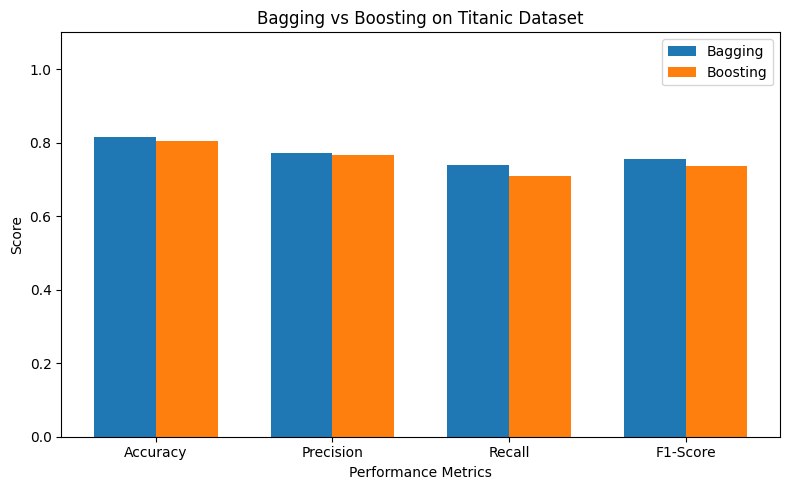

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate performance metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

bagging_scores = [
    accuracy_score(y_test, y_pred_bag),
    precision_score(y_test, y_pred_bag),
    recall_score(y_test, y_pred_bag),
    f1_score(y_test, y_pred_bag)
]

boosting_scores = [
    accuracy_score(y_test, y_pred_boost),
    precision_score(y_test, y_pred_boost),
    recall_score(y_test, y_pred_boost),
    f1_score(y_test, y_pred_boost)
]

# Create bar graph
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, bagging_scores, width, label='Bagging')
plt.bar(x + width/2, boosting_scores, width, label='Boosting')

plt.xlabel('Performance Metrics')
plt.ylabel('Score')
plt.title('Bagging vs Boosting on Titanic Dataset')
plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.legend()

plt.tight_layout()
plt.show()